# Are the small tilt tolerances real, or a mistake in the calculation?

Every number here comes from the **newest data and analysis**, the same as the `corrected_final` figures:

- **One set of simulations for both methods.** The 4096-grid, full-detector short-range sims (41 tilts,
  ±0.6°, 0.03° step) carry the Kikuchi bands *and* the Bragg disks, so the Kikuchi COM and the disk pairs
  are measured on identical patterns. The 1024-grid `*_disks.npz` sims are not used (not grid-converged).
- **Corrected Kikuchi metric** (`kikuchi_com`): exact mirror box, masked union COM. Boxes 108–208 mrad
  (PTO, BTO) and 40–100 mrad (boracite, whose aperture is at 154 mrad), and boracite's true
  abTEM box `BORACITE_EXTENT` = 169.3 Å.
- **Lattice-centred disk ROIs** (`disk_row_box`, `DISK_LATTICE`).
- **Paper frame** (`corrected_final`): positive = towards the side P points to (the top box), PTO
  mirrored with y(t) → −y(−t), tilt axis plotted with `TILT_SIGN = −1`. Images and maps are shown *as
  simulated*.
- **Failure angle** = the tilt nearest zero at which a curve changes sign from its zero-tilt value
  (linear interpolation), both directions; tolerance = the smaller of the two.
- **Error model**: the tilt-to-tilt structure is deterministic, so the control is the same metric on the
  non-polar axis, not an SEM across tilt.

## Answer

**No, the calculations are not wrong, and the small tolerances are what dynamical diffraction predicts
for these crystals at this thickness.**

1. **Every part of the pipeline checks out (§1).** The Kikuchi pattern moves by the predicted
   105 px/deg (PTO, BTO) and 150 px/deg (boracite, which also confirms its 169.3 Å box), within 1–2 %, along the polar
   axis only, so tilt units, axis and calibration are right. The disk interiors at ±0.03° are the
   zero-tilt interiors slid by the predicted amount to within 0.15 px (0.8 px boracite), so neighbouring
   simulations are consistent. An independent PTO simulation reproduces the curve (r = 0.9999). The long-range sims
   (a different step) give the same Δ₀ and failure angles, and the non-polar control is 20–100× flatter.
   The notebook reproduces every number in the paper.
2. **The scale is set by large-G reflections, not by the probe or the analysis (§2).**
   Parallel-beam rocking curves rebuilt from the disk interiors change sign within 0.005–0.04°, and
   widening the probe to 2.5 mrad does not help in general. The low-order reflections alone would give 0.2–0.4°
   tolerances, the size one might naively expect. The measured 0.005–0.18° are instead of the order of
   1/(G t) ≈ 0.02–0.04° for the first-order Laue zone at 50–60 nm thickness.
3. **The Kikuchi COM fails first (§3) because its signal is a 1–3 % box/mirror imbalance.** A tilt along
   P breaks the ±q symmetry at first order, so a slide of the pattern by only 1.6–9 px reverses the
   reading. Box position, pixel size and soft edges do not change this; crystal-fixed boxes help BTO and
   boracite (to 0.07°) but not PTO.
4. **Ways to a more robust measurement, all in the data:** tilt about P is harmless (≥ 0.3–0.6°, §4);
   domain contrast (the even part) survives longer (§5); and the best disk ROI beats Kikuchi in every
   material (§6).

**Untested predictions:** a tilt sweep at a smaller thickness (for example 20–30 nm) should widen the
tolerances roughly as 1/t. The zero-tilt thickness series cannot test this; it needs tilts.

In [1]:
import io
import os
import zipfile

import numpy as np
import matplotlib.pyplot as plt

plt.style.use("paper")   # ~/.config/matplotlib/stylelib

from polarisation_direction import P_REVERSED
from kikuchi_com import (N, FULL_BOX, BORACITE_EXTENT, DISK_LATTICE, angular_box, disk_row_box,
                         masked_com, mirror_box, stream_patterns)

_h, _m, _e, _c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0
LAMBDA = _h / np.sqrt(2*_m*_e*300e3) / np.sqrt(1 + _e*300e3/(2*_m*_c**2)) * 1e10   # 0.019687 A
ALPHA = 0.8              # probe convergence semi-angle in every sim script, mrad
DATA = {
    "PTO": "data/short_range/PTO_short_range_21_sept_asymmetry_data.npz",
    "BTO": "data/short_range/BTO_kikuchi_final_15_slice_asymmetry_data.npz",
    "Boracite": "data/short_range/1_slice_thickness/boracite_kikuchi_1_slice_asymmetry_data.npz",
}
PTO_RUN2 = "data/INCOMPLETE_PTO_kikuchi_final_asymmetry_data.npz"   # independent PTO run, same settings
EXTENT = {"PTO": 30 * 3.9423, "BTO": 30 * 4.0230, "Boracite": BORACITE_EXTENT}   # abTEM box along P, A
KPP = {k: 1 / EXTENT[k] for k in DATA}                                           # A^-1 per px
MPP = {k: LAMBDA * KPP[k] * 1e3 for k in DATA}                                   # mrad per px
PXDEG = {k: np.pi / 180 * 1e3 / MPP[k] for k in DATA}      # px the crystal-fixed pattern moves per deg
# Kikuchi boxes of the paper: 108-208 mrad for PTO/BTO; boracite 40-100 mrad
BOX = {"PTO": FULL_BOX, "BTO": FULL_BOX,
       "Boracite": angular_box(MPP["Boracite"], MPP["Boracite"], (40.0, 100.0))}
assert BOX["Boracite"] == (1188, 1705, 1962, 2134)
THICK = {"PTO": 598, "BTO": 614, "Boracite": 484}           # specimen thickness, A (05_methods.md)
BEAM_REPEAT = {"PTO": 3.8862, "BTO": 3.9905, "Boracite": 12.10}   # lattice repeat along the beam, A
COLOURS = dict(zip(DATA, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
GREY = "#9a9a96"
CACHE = "cache_investigation"
os.makedirs(CACHE, exist_ok=True)
r = np.arange(N)
CW = 320                                   # half-size of the central (disk) crop, px
OFF = N // 2 - CW                          # crop origin in full-pattern pixels


def tilts(path):
    with zipfile.ZipFile(path).open("tilt_y_values.npy") as h:
        return np.load(io.BytesIO(h.read()))


def profiles(name):
    """Per tilt: the polar-axis profile summed over the box columns (all the box metric
    ever sees), the same for the non-polar axis, a crop around the box, and a central crop
    holding the Bragg disks. One streaming pass over the 5.5 GB file, then cached."""
    f = os.path.join(CACHE, f"{name}_profiles.npz")
    lo, hi, x0, x1 = BOX[name]
    if os.path.exists(f):
        d = np.load(f)
        if "box" in d.files and tuple(d["box"]) == BOX[name] and "centre" in d.files:
            return {k: d[k] for k in d.files}
    p0, p1, crop, centre = [], [], [], []
    for p in stream_patterns(DATA[name]):
        p0.append(p[:, x0:x1].sum(axis=1))
        p1.append(p[x0:x1, :].sum(axis=0))          # masked_com(axis=1) sees exactly this
        crop.append(p[lo - 200:hi + 200, N//2 - 200:N//2 + 200].astype(np.float32))
        centre.append(p[N//2 - CW:N//2 + CW, N//2 - CW:N//2 + CW].astype(np.float32))
    out = dict(tilt=tilts(DATA[name]), box=np.array(BOX[name]), prof0=np.array(p0),
               prof1=np.array(p1), crop=np.array(crop), centre=np.array(centre))
    np.savez(f, **out)
    return out


def run2_com():
    """Corrected COM of the independent PTO run (same box), for the reproducibility check."""
    f = os.path.join(CACHE, "PTO_run2_com.npz")
    if not os.path.exists(f):
        com = [masked_com(p, FULL_BOX) if p.sum() > 0 else np.nan for p in stream_patterns(PTO_RUN2)]
        np.savez(f, tilt=tilts(PTO_RUN2), com=np.array(com))
    d = np.load(f)
    return d["tilt"], d["com"]


def metric(P, box):
    """Corrected masked COM (kikuchi_com.masked_com) on profiles: centroid of the box rows
    and their exact mirror, minus N/2, in px. Raw sign: + towards higher row index."""
    lo, hi = box[:2]
    a0, a1 = N + 1 - hi, N + 1 - lo
    num = (P[:, lo:hi] * r[lo:hi]).sum(1) + (P[:, a0:a1] * r[a0:a1]).sum(1)
    return num / (P[:, lo:hi].sum(1) + P[:, a0:a1].sum(1)) - N / 2


def paper(name, t, y):
    """(tilt as simulated, value with + = top box) -> (plotted tilt, value in the paper frame).
    P points to the top box: PTO (built with P to the bottom) is mirrored, y(t) -> -y(-t); then
    the tilt axis is plotted with TILT_SIGN = -1. Works on non-symmetric grids."""
    if P_REVERSED[name]:
        return -t[::-1], y[::-1]
    return t, -y


def first_flip(t, y):
    """|tilt| nearest zero on each side where y changes sign from y(0), linear interpolation.
    Returns (minus side, plus side); inf if the sign holds to the end of the sweep."""
    i0 = int(np.argmin(abs(t))); s0 = np.sign(y[i0]); out = []
    for step in (-1, 1):
        i, hit = i0, np.inf
        while 0 <= i + step < len(t):
            j = i + step
            if np.sign(y[j]) != s0:
                hit = abs(t[i] + (t[j] - t[i]) * y[i] / (y[i] - y[j]))
                break
            i = j
        out.append(hit)
    return tuple(out)


def even_odd(y):
    """Even and odd parts on a symmetric tilt grid."""
    return (y + y[::-1]) / 2, (y - y[::-1]) / 2


def disk_boxes(name, order, n):
    (y0, y1), (x0, x1) = disk_row_box((N, N), *DISK_LATTICE[name], order, n)
    return (y0, y1, x0, x1), mirror_box((y0, y1, x0, x1))


def disk_asym(name, order, n):
    """Friedel-pair asymmetry (top - bottom)/(top + bottom), %, on the same 4096 patterns."""
    C = prof[name]["centre"].astype(np.float64)
    (b1, b2) = disk_boxes(name, order, n)
    s = [C[:, y0 - OFF:y1 - OFF, x0 - OFF:x1 - OFF].sum((1, 2)) for y0, y1, x0, x1 in (b1, b2)]
    return (s[0] - s[1]) / (s[0] + s[1]) * 100


fmt = lambda f: "none" if np.isinf(f) else f"{f:.3f}°"
ROIS = {k: [(o, n) for o in (1, 2, 3) for n in (1, 3, 5) if not (k == "Boracite" and o == 3)] for k in DATA}

prof = {k: profiles(k) for k in DATA}
T = prof["PTO"]["tilt"]
assert all(np.allclose(prof[k]["tilt"], T) for k in DATA) and np.allclose(T, -T[::-1])
com = {k: metric(prof[k]["prof0"], BOX[k]) for k in DATA}        # raw px
ctrl = {k: metric(prof[k]["prof1"], BOX[k]) for k in DATA}       # same metric, non-polar axis
TAU = paper("PTO", T, T)[0]                                       # plotted tilt axis (symmetric)
kik = {k: paper(k, T, -com[k])[1] for k in DATA}                  # paper frame, px
kik_ctrl = {k: paper(k, T, -ctrl[k])[1] for k in DATA}
disk = {k: {roi: paper(k, T, disk_asym(k, *roi))[1] for roi in ROIS[k]} for k in DATA}
whole = {k: paper(k, T, -np.load(f"figure_notebooks/cache_shortrange/{k}.npz")["mismatch"])[1] for k in DATA}
i0 = int(np.argmin(abs(TAU)))

# ── does this reproduce the paper (Results)? ─────────────────────────────────────
for k in DATA:   # the profile metric must equal the full-pattern metric of the figure notebooks
    ref = np.load(f"figure_notebooks/cache_shortrange/{k}.npz")
    assert np.allclose(com[k], ref["com"]) and np.allclose(ctrl[k], ref["ctrl"]), k
PAPER_KIK = {"PTO": (0.205, 0.090, 0.311), "BTO": (0.068, 0.015, np.inf), "Boracite": (-0.074, np.inf, 0.020)}
PAPER_DISK = {"PTO": ((1, 3), -31.2, np.inf, 0.140), "BTO": ((1, 3), -39.3, 0.042, 0.114),
              "Boracite": ((1, 1), -68.6, 0.176, 0.460)}
for k in DATA:
    d0, m, p = PAPER_KIK[k]
    assert round(kik[k][i0] * KPP[k], 3) == d0 and np.allclose(first_flip(TAU, kik[k]), (m, p), atol=6e-4), k
    roi, d0, m, p = PAPER_DISK[k]
    assert round(disk[k][roi][i0], 1) == d0 and np.allclose(first_flip(TAU, disk[k][roi]), (m, p), atol=6e-4), k
print("reproduces the paper: Kikuchi Delta_0 and failure angles, best disk ROI values and failure angles")

reproduces the paper: Kikuchi Delta_0 and failure angles, best disk ROI values and failure angles


## 1 · Is there a mistake in the calculation?

### 1a · Tilt units, axis and sign

If `tilt_y_values` were in the wrong unit (radians, mrad) or the rotation acted on the wrong axis,
every tolerance would be off by a large factor. The Kikuchi pattern is fixed to the crystal, so a
crystal tilt $t$ must slide it by exactly $t/(\lambda/L)$ along the polar axis (axis 0) and not at all
across it. Measured by phase-correlating the band-passed pattern at each tilt with the zero-tilt one:

In [2]:
BIN = 8                                    # 4096 -> 512 px thumbnails
flip_idx = (N - r) % N                     # row/col index of -q (centre at N/2, see kikuchi_com)


def thumbs(name):
    """Per tilt: 8x-binned pattern and 8x-binned Friedel difference I(q) - I(-q).
    The difference is taken at full resolution before binning so the mirror stays exact.
    Second streaming pass over the file, then cached (independent of the box)."""
    f = os.path.join(CACHE, f"{name}_thumbs.npz")
    if os.path.exists(f):
        d = np.load(f)
        return {k: d[k] for k in d.files}
    b = lambda a: a.reshape(N // BIN, BIN, N // BIN, BIN).sum((1, 3)).astype(np.float32)
    img, dif = [], []
    for p in stream_patterns(DATA[name]):
        img.append(b(p)); dif.append(b(p - p[flip_idx][:, flip_idx]))
    out = dict(img=np.array(img), dif=np.array(dif))
    np.savez(f, **out)
    return out


thumb = {k: thumbs(k) for k in DATA}
for k in DATA:   # thumbnails must bin the same patterns as the cached central crop
    c = prof[k]["centre"][:, 64:576, 64:576].reshape(-1, 64, BIN, 64, BIN).sum((2, 4))
    assert np.allclose(thumb[k]["img"][:, 256 - 32:256 + 32, 256 - 32:256 + 32], c, rtol=1e-4), k


def pattern_shift(name):
    """(axis-0, axis-1) displacement of the Kikuchi pattern from zero tilt, full-res px.
    High-pass (sigma 4 thumb px) inside the aperture, outside the disk region."""
    from scipy.ndimage import gaussian_filter
    img = thumb[name]["img"].astype(np.float64)
    yy, xx = np.mgrid[:512, :512]
    R = np.hypot(yy - 256, xx - 256)
    m = (R > 20) & (R < 0.9 * N / 3 / BIN)
    hp = lambda a: np.where(m, np.log(a) - gaussian_filter(np.log(a), 4), 0)
    F0 = np.fft.fft2(hp(img[i0]))
    out = []
    for a in img:
        c = np.fft.fftshift(np.fft.ifft2(np.fft.fft2(hp(a)) * F0.conj()).real)
        j = np.unravel_index(np.argmax(c), c.shape)
        sub = []
        for ax, e in ((0, (1, 0)), (1, (0, 1))):              # parabolic sub-pixel peak
            lo, hi = c[tuple(np.subtract(j, e))], c[tuple(np.add(j, e))]
            sub.append(j[ax] - 256 + 0.5 * (lo - hi) / (lo - 2 * c[j] + hi))
        out.append(sub)
    return np.array(out) * BIN


print(f"{'':9s} {'predicted':>10s} {'measured':>10s} {'across P':>9s}   (px per deg of tilt_y)")
for k in DATA:
    s = pattern_shift(k)
    m0, m1 = np.polyfit(T, s[:, 0], 1)[0], np.polyfit(T, s[:, 1], 1)[0]
    alt = f"   [119.7 A box would predict {np.pi/180*1e3/(LAMBDA/(7*17.1032)*1e3):.0f}]" if k == "Boracite" else ""
    print(f"{k:9s} {PXDEG[k]:10.1f} {m0:10.1f} {m1:9.1f}{alt}")

           predicted   measured  across P   (px per deg of tilt_y)


PTO            104.8      106.1      -0.0


BTO            107.0      108.0      -0.0


Boracite       150.1      151.9       0.0   [119.7 A box would predict 106]


The pattern moves by the predicted amount (within 1–2 %), along the polar axis only, and in the same
direction for all three materials. A wrong unit would be off by 57× (radians) or 1000× (mrad). So the tilts are in degrees, they act on the polar axis, and the reciprocal
calibration (including boracite's 169.3 Å box) is right.

### 1b · Internal consistency of the tilt series

The probe has a semi-angle α = 0.8 mrad = 0.046°, so each disk is a small map of incidence
directions: a pixel offset φ inside a disk sees the crystal at incidence φ relative to the disk
centre. A crystal tilt $t$ must therefore reproduce the zero-tilt disk interiors **slid by
$c\,t$** (c = px/deg above), wherever the two cones overlap. This links neighbouring simulations
through the physics alone, with no fitted parameter:

In [3]:
def disk_rowprofile(name, i, cy):
    C = prof[name]["centre"]
    return C[i, cy - 12:cy + 13, CW - 1:CW + 2].sum(1).astype(np.float64)


x = np.arange(-12, 13)
print(f"{'':9s} {'disk diameter':>14s} | slide that best maps zero tilt onto t = -0.03 / +0.03 deg (px)")
for k in DATA:
    s, _ = DISK_LATTICE[k]; rad = ALPHA / MPP[k]
    z = disk_rowprofile(k, i0, CW)
    edge = x[(z / z.max() > 0.5)]
    line = f"{k:9s} {edge.max() - edge.min() + 1:7d} px ({2*rad:4.1f}) |"
    worst = 0
    for order in (-1, 0, 1):
        cy = CW - order * s
        for t in (-0.03, 0.03):
            i = int(np.argmin(abs(T - t))); best = (np.inf, 0)
            for d in np.arange(-rad, rad, 0.05):
                m = (abs(x) <= rad - 1) & (abs(x - d) <= rad - 1)
                ref = np.interp(x[m] - d, x, disk_rowprofile(k, i0, cy))
                e = np.sqrt(np.mean((disk_rowprofile(k, i, cy)[m] - ref) ** 2)) / ref.max()
                best = min(best, (e, d))
            line += f" {best[1]:+.2f}"; worst = max(worst, best[0])
    print(line + f" | predicted {-0.03*PXDEG[k]:+.2f}/{0.03*PXDEG[k]:+.2f}, worst rms residual {worst:.1%}")

           disk diameter | slide that best maps zero tilt onto t = -0.03 / +0.03 deg (px)
PTO             9 px ( 9.6) | -3.16 +3.29 -3.16 +3.04 -3.21 +3.14 | predicted -3.15/+3.15, worst rms residual 0.3%
BTO             9 px ( 9.8) | -3.15 +3.15 -3.15 +3.20 -3.25 +3.15 | predicted -3.21/+3.21, worst rms residual 0.5%
Boracite       13 px (13.8) | -4.63 +4.52 -5.08 +5.32 -4.48 +4.32 | predicted -4.50/+4.50, worst rms residual 2.0%


For the disks of orders −1, 0, +1, the tilted interiors are the zero-tilt interiors slid by c·t: to
within 0.15 px (≤ 0.5 % residual) for PTO and BTO, and within 0.8 px (2 % residual, worst for the
central disk) for boracite. Neighbouring simulations agree with each other at the 0.01° level. It also shows how little 0.03° is: one tilt step slides
the incidence cone by 65 % of its radius, and from 0.06° on (2 × 0.046° = 0.092° for no overlap at all)
the tilted probe shares almost no incidence direction with the zero-tilt one.

### 1c · Reproducibility, noise and sampling

In [4]:
t2, c2 = run2_com()
assert np.allclose(t2, T)
ok = np.isfinite(c2)
print(f"independent PTO run: r = {np.corrcoef(com['PTO'][ok], c2[ok])[0,1]:.4f}, "
      f"rms difference {np.std(com['PTO'][ok] - c2[ok]):.2f} px against a {com['PTO'].std():.0f} px curve; "
      f"failure angles {fmt(first_flip(*paper('PTO', T, -c2))[0])} / {fmt(first_flip(*paper('PTO', T, -c2))[1])}")

print(f"\n{'':9s} {'even-part rms, polar':>21s} {'non-polar':>10s}   (px; the non-polar axis is the noise floor)")
for k in DATA:
    ep, ec = even_odd(kik[k])[0][TAU > 0], even_odd(kik_ctrl[k])[0][TAU > 0]
    print(f"{k:9s} {ep.std(ddof=1):21.2f} {ec.std(ddof=1):10.2f}")

print(f"\nlong range (independent sims, 0.0625 deg step) vs short range (0.03 deg):")
for k in DATA:
    L = np.load(f"figure_notebooks/cache_longrange/{k}.npz")
    tl, yl = paper(k, L["tilt"], -L["com"])
    j0 = int(np.argmin(abs(tl)))
    f_s, f_l = first_flip(TAU, kik[k]), first_flip(tl, yl)
    print(f"{k:9s} Delta_0 {kik[k][i0]*KPP[k]:+.3f} / {yl[j0]*KPP[k]:+.3f} A^-1 | "
          f"flips {fmt(f_s[0])} {fmt(f_s[1])}  /  {fmt(f_l[0])} {fmt(f_l[1])}")

independent PTO run: r = 0.9999, rms difference 0.71 px against a 41 px curve; failure angles 0.089° / 0.310°

           even-part rms, polar  non-polar   (px; the non-polar axis is the noise floor)
PTO                       22.21       0.21
BTO                       10.48       0.29
Boracite                   7.44       0.38

long range (independent sims, 0.0625 deg step) vs short range (0.03 deg):
PTO       Delta_0 +0.205 / +0.204 A^-1 | flips 0.090° 0.311°  /  0.085° 0.309°
BTO       Delta_0 +0.068 / +0.068 A^-1 | flips 0.015° none  /  0.018° 0.803°
Boracite  Delta_0 -0.074 / -0.073 A^-1 | flips none 0.020°  /  0.757° 0.020°


- A second, independent PTO simulation reproduces the curve point for point. The structure is
  deterministic dynamical scattering, not phonon noise.
- On the non-polar axis the even part is 20–100× smaller. The metric is not noisy.
- The long-range sweep is a different set of simulations with a different step, and it gives the same
  Δ₀ and the same failure angles within 0.005°. The failures at 0.015–0.02° (BTO, boracite) lie inside
  the first 0.03° step, so they are interpolated, but two grids agree on them.

**No calculation error found.** The tilts, axes, calibrations, metric, sign conventions and sampling
all check out. The question becomes whether the small tolerances are expected physically.

## 2 · What sets the tilt scale?

### 2a · Parallel-beam rocking curves from the disk interiors

By §1b every disk row is an extra sample of the tilt sweep: row φ at tilt t sees the incidence of the
disk centre at tilt t − φ/c. Pooling the rows of all 41 patterns gives each disk's intensity against
incidence at 1-px resolution (0.0095° PTO/BTO, 0.0067° boracite), i.e. what a **parallel beam** would
measure. Averaging it back over a disk of radius α reproduces the 1×1 ROI, which closes the loop.
Averaging over a larger disk predicts what a **larger convergence angle** would give, up to the angle
at which disks overlap (2.5 mrad PTO/BTO, 1.6 mrad boracite). This last step assumes that incidence
*across* P (not sampled by the sweep) averages the same way, so treat it as an estimate.

                         α = 0.0 mrad          α = 0.8 mrad          α = 1.6 mrad          α = 2.5 mrad        1x1 ROI (real)
PTO       {100}    +11.6% 0.006°     +8.7% 0.006°     +4.1% 0.005°     -0.3% 0.001°     +9.4% 0.008°


PTO       {200}    -94.9% 0.038°    -73.2% 0.038°    -53.2% 0.040°    -46.1% 0.057°    -74.5% 0.042°


BTO       {100}     +3.0% 0.005°    +10.0% 0.013°    +18.4% 0.031°    +23.3% 0.287°    +10.2% 0.016°
BTO       {200}    -66.4% 0.014°    -46.2% 0.016°    -32.8% 0.024°    -30.7% 0.046°    -47.1% 0.018°


Boracite  {100}    -70.1% 0.175°    -69.2% 0.178°    -65.2% 0.190°                          -68.6% 0.176°
Boracite  {200}    -29.4% 0.016°    -27.3% 0.015°    -22.5% 0.015°                          -26.8% 0.015°


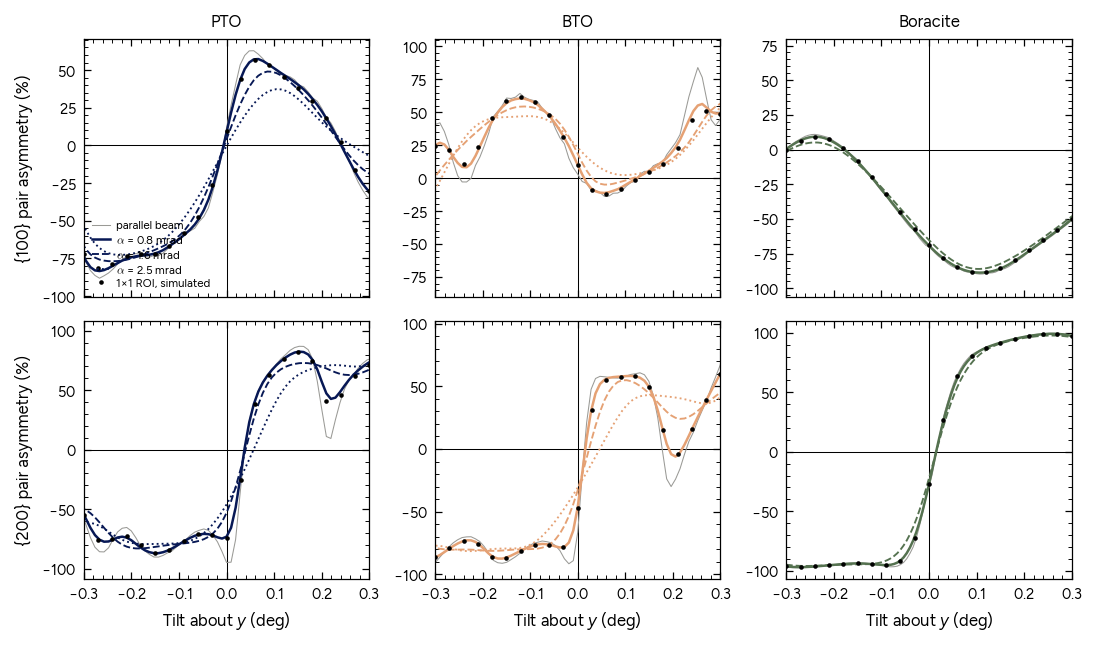

(each entry: value at zero tilt, tolerance = nearest sign change)


In [5]:
def rocking(name, order):
    """Parallel-beam intensity of the +g (top) and -g (bottom) central disks of row `order`
    against tilt, pooled from every disk row of every pattern. Rows are divided by their chord."""
    C = prof[name]["centre"].astype(np.float64)
    s, half = DISK_LATTICE[name]
    c, rad = PXDEG[name], ALPHA / MPP[name]
    phis = np.arange(-int(rad - 1), int(rad - 1) + 1)          # keep clear of the disk edge
    K = int(np.ceil(T.max() * c)) + phis.max() + 1
    tf = np.arange(-K, K + 1) / c
    J = []
    for cy in (N // 2 - order * s - OFF, N // 2 + order * s - OFF):
        acc, cnt = np.zeros(len(tf)), np.zeros(len(tf))
        for phi in phis:
            row = C[:, cy + phi, CW - half:CW + half + 1].sum(1) / (2 * np.sqrt(rad**2 - phi**2))
            j = np.rint(T * c - phi).astype(int) + K
            np.add.at(acc, j, row); np.add.at(cnt, j, 1)
        J.append(np.where(cnt > 0, acc / np.maximum(cnt, 1), np.nan))
    return tf, J[0], J[1]


def cone_asym(name, tf, Jt, Jb, alpha):
    """Asymmetry (%) for a probe of semi-angle alpha (mrad): chord-weighted average over the disk.
    alpha = 0 is the parallel beam. Returns the plotted tilt and the paper-frame value, cropped
    symmetrically to where the average is fully covered by data."""
    n = int(alpha / MPP[name])
    w = np.sqrt(np.clip((alpha / MPP[name]) ** 2 - np.arange(-n, n + 1) ** 2, 0, None)) if n else np.ones(1)
    It, Ib = (np.convolve(J, w / w.sum(), mode="same") for J in (Jt, Jb))
    valid = np.convolve(np.isfinite(Jt + Jb), np.ones(2 * n + 1), mode="same") == 2 * n + 1
    L = min(np.argmax(valid), np.argmax(valid[::-1]))
    sl = slice(L, len(tf) - L)
    return paper(name, tf[sl], ((It - Ib) / (It + Ib) * 100)[sl])


ALPHAS = {"PTO": (0, ALPHA, 1.6, 2.5), "BTO": (0, ALPHA, 1.6, 2.5), "Boracite": (0, ALPHA, 1.6)}
fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.2), sharex=True, layout="constrained")
print(f"{'':15s}" + "".join(f"{'α = ' + format(a, '.1f') + ' mrad':>22s}" for a in (0, ALPHA, 1.6, 2.5))
      + f"{'1x1 ROI (real)':>22s}")
for col, k in enumerate(DATA):
    for row, order in enumerate((1, 2)):
        tf, Jt, Jb = rocking(k, order)
        ax = axes[row, col]
        ax.axhline(0, color="black", lw=0.5); ax.axvline(0, color="black", lw=0.5)
        line = f"{k:9s} {{{order}00}}"
        for a, ls, lw in zip(ALPHAS[k], ("-", "-", "--", ":"), (0.5, 1.2, 0.9, 0.9)):
            tp, v = cone_asym(k, tf, Jt, Jb, a)
            f = first_flip(tp, v)
            line += f"   {v[np.argmin(abs(tp))]:+6.1f}% {min(f):.3f}°"
            ax.plot(tp, v, ls=ls, lw=lw, color=COLOURS[k] if a else GREY,
                    label=("parallel beam" if a == 0 else rf"$\alpha$ = {a:.1f} mrad"))
        real = disk[k][(order, 1)]
        ax.plot(TAU, real, "o", ms=2.2, mew=0, color="black", label="1×1 ROI, simulated")
        f = first_flip(TAU, real)
        line += " " * 22 * (4 - len(ALPHAS[k]))                 # boracite: no 2.5 mrad column
        print(line + f"   {real[i0]:+6.1f}% {min(f):.3f}°")
        ax.set_xlim(-0.3, 0.3)
        if row == 0: ax.set_title(k)
        if row == 1: ax.set_xlabel("Tilt about $y$ (deg)")
        if col == 0: ax.set_ylabel(f"{{{order}00}} pair asymmetry (%)")
axes[0, 0].legend(fontsize="x-small", loc="lower left")
plt.show()
print("(each entry: value at zero tilt, tolerance = nearest sign change)")

- **Closure:** the α = 0.8 mrad average of the reconstructed curves sits on the simulated 1×1 ROI
  points (black) and gives the same zero-tilt values and failure angles. The reconstruction is valid.
- **Parallel beam:** the Friedel-pair asymmetry itself changes sign within **0.005–0.04°** for every
  reflection except boracite {100}. The finite probe is not what makes it fragile.
- **Larger convergence angle:** averaging over up to 2.5 mrad smooths the curves. It moves most failure
  angles by only 0.00–0.03°. One reflection gains (BTO {100}: 0.29° at 2.5 mrad), and one loses its
  zero-tilt signal altogether (PTO {100}: −0.3 %). A larger condenser aperture is therefore no general
  fix.
- Every curve passes steeply through or near zero close to zero tilt. That is the odd, geometric term of
  §3: zero tilt sits on a steep flank, so the nearest sign change is close.

### 2b · The angular scales of the problem

In [6]:
print(f"{'':9s} {'probe α':>8s} {'θ_B first':>10s} {'1/(g t) {100}':>14s} {'{200}':>7s} "
      f"{'FOLZ G':>8s} {'1/(G t)':>8s} | {'Kikuchi':>8s} {'best disk':>9s}   (deg unless stated)")
for k in DATA:
    s, _ = DISK_LATTICE[k]
    g = s * KPP[k]                                            # first disk along P, A^-1
    G = np.sqrt(2 / (LAMBDA * BEAM_REPEAT[k]))                # first-order Laue zone radius, A^-1
    deg = lambda rad: np.degrees(rad)
    tk = min(first_flip(TAU, kik[k]))
    td = max(min(first_flip(TAU, v)) for v in disk[k].values())
    print(f"{k:9s} {deg(ALPHA*1e-3):8.3f} {deg(LAMBDA*g/2):10.3f} {deg(1/(g*THICK[k])):14.3f} "
          f"{deg(1/(2*g*THICK[k])):7.3f} {G:6.2f}/Å {deg(1/(G*THICK[k])):8.3f} | {tk:8.3f} {td:9.3f}")

           probe α  θ_B first  1/(g t) {100}   {200}   FOLZ G  1/(G t) |  Kikuchi best disk   (deg unless stated)
PTO          0.046      0.143          0.378   0.189   5.11/Å    0.019 |    0.090     0.140
BTO          0.046      0.140          0.375   0.188   5.05/Å    0.018 |    0.015     0.052
Boracite     0.046      0.093          0.716   0.358   2.90/Å    0.041 |    0.020     0.176


A tilt θ changes the excitation error of a reflection G by about Gθ, and the intensity of a thick
crystal changes on the scale where that phase, s·t, changes by order one: Δθ ~ 1/(G t).
- For the low-order reflections themselves ({100}, {200}) that scale is 0.2–0.4° (two-beam rocking).
  If those alone mattered, the methods would tolerate tenths of a degree, as earlier expected.
- Most measured tolerances (0.005–0.05°) are an order of magnitude smaller, and even the best ROIs
  (0.14–0.18°) are 2–4× smaller. They are of the order of **1/(G t) for the first-order Laue zone**
  (G ≈ 5 Å⁻¹ for PTO/BTO along [100], 2.9 Å⁻¹ for boracite along [110]): 0.019° and 0.041°. At a ~50–60 nm thickness, the zone-axis pattern is coupled to these large-G
  reflections, and both the disk Friedel asymmetry and the Kikuchi intensity balance inherit their
  rocking width. For the Kikuchi boxes this is direct: they sit on or just outside the FOLZ ring
  (≈100 mrad PTO/BTO, ≈57 mrad boracite; drawn in §3).
- Consequence: the tolerance should scale as **1/thickness**, and a thinner specimen should be more
  forgiving. This is a prediction, not yet tested (the thickness series is at zero tilt only).

## 3 · Why the Kikuchi COM fails earliest

Paper frame. Shaded band: ±|Δ₀| about Δ₀. Grey: the same metric on the non-polar axis.

           Delta0 (A^-1)  slope (A^-1/deg)   flip -   flip +  pattern slide at failure
PTO               +0.205             +1.50   0.090°   0.311°          9.4 px of a 600 px box
BTO               +0.068             +3.56   0.015°     none          1.6 px of a 600 px box
Boracite          -0.074             +3.50     none   0.020°          3.0 px of a 517 px box


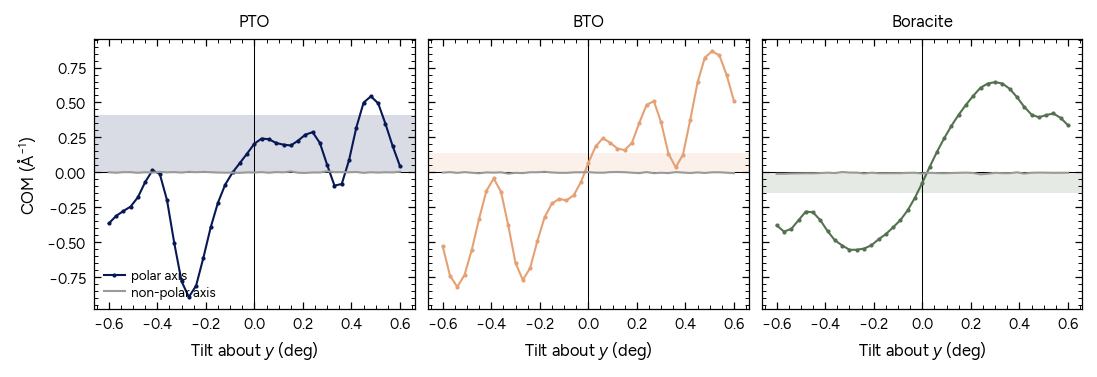

In [7]:
print(f"{'':9s} {'Delta0 (A^-1)':>14s} {'slope (A^-1/deg)':>17s} {'flip -':>8s} {'flip +':>8s} "
      f"{'pattern slide at failure':>25s}")
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.4), sharey=True)
for ax, k in zip(axes, DATA):
    y = kik[k] * KPP[k]; y0 = y[i0]
    slope = np.polyfit(TAU[abs(TAU) <= 0.061], y[abs(TAU) <= 0.061], 1)[0]
    f = first_flip(TAU, y)
    print(f"{k:9s} {y0:+14.3f} {slope:+17.2f} {fmt(f[0]):>8s} {fmt(f[1]):>8s} "
          f"{min(f) * PXDEG[k]:12.1f} px of a {BOX[k][1] - BOX[k][0]} px box")
    ax.axhspan(y0 - abs(y0), y0 + abs(y0), color=COLOURS[k], alpha=0.15, lw=0)
    ax.axhline(0, color="black", lw=0.5); ax.axvline(0, color="black", lw=0.5)
    ax.plot(TAU, y, "-o", ms=2, color=COLOURS[k], mew=0, label="polar axis")
    ax.plot(TAU, kik_ctrl[k] * KPP[k], "-", color=GREY, label="non-polar axis")
    ax.set_title(k); ax.set_xlabel("Tilt about $y$ (deg)")
axes[0].set_ylabel(r"COM ($\mathrm{\AA}^{-1}$)"); axes[0].legend(loc="lower left")
plt.show()

The Kikuchi pattern only has to slide by **1.6 px (BTO) to 9 px (PTO)** across a 500–600 px box for
the reading to change sign. The zero-tilt offset is tiny next to the tilt response.

### What the metric is actually measuring

The union centroid splits exactly into the midpoint of the two box centroids plus an
intensity-imbalance term:

$$y = \underbrace{\tfrac{c_1+c_2}{2} - \tfrac N2}_{\text{line positions}} + \underbrace{\tfrac{c_1-c_2}{2}\,\frac{I_1-I_2}{I_1+I_2}}_{\text{brightness imbalance}}$$

In [8]:
def split(P, box):
    lo, hi = box[:2]
    a0, a1 = N + 1 - hi, N + 1 - lo
    I1, I2 = P[:, lo:hi].sum(1), P[:, a0:a1].sum(1)
    c1 = (P[:, lo:hi] * r[lo:hi]).sum(1) / I1
    c2 = (P[:, a0:a1] * r[a0:a1]).sum(1) / I2
    return (c1 + c2) / 2 - N / 2, (c1 - c2) / 2 * (I1 - I2) / (I1 + I2), (I1 - I2) / (I1 + I2), (c1 - c2) / 2


print(f"{'':9s} {'var: imbalance':>15s} {'var: positions':>15s} {'lever (px)':>11s} "
      f"{'|imbalance| at 0':>17s} {'per 0.1 deg':>12s}")
for k in DATA:
    mid, imb, a, lever = split(prof[k]["prof0"], BOX[k])
    assert np.allclose(mid + imb, com[k])
    s = np.polyfit(T[abs(T) <= 0.061], a[abs(T) <= 0.061], 1)[0]
    print(f"{k:9s} {imb.var()/com[k].var():15.1%} {mid.var()/com[k].var():15.1%} {lever.mean():11.0f} "
          f"{abs(a[i0]):17.2%} {abs(s)*0.1:11.2%}")

           var: imbalance  var: positions  lever (px)  |imbalance| at 0  per 0.1 deg
PTO                104.4%            0.1%        -832             2.90%       2.20%
BTO                106.3%            0.1%        -827             0.98%       5.21%
Boracite           101.9%            0.0%        -486             2.70%      12.25%


Essentially all of the curve is brightness imbalance between the box and its mirror (shares above
100 % mean the two terms are slightly anti-correlated). The polar signal is a 1–3 % imbalance; 0.1°
of tilt produces 2.2 % (PTO), 5.2 % (BTO) and 12 % (boracite).

### Where the imbalance comes from

Box and mirror profiles against tilt (as simulated), relative to their tilt-average:

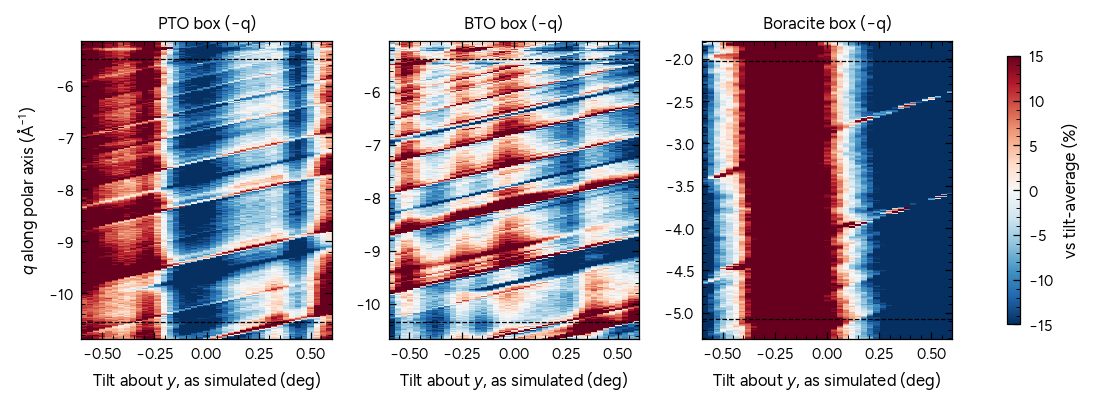

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.6), layout="constrained")
for ax, k in zip(axs, DATA):
    lo, hi = BOX[k][:2]; kpp = KPP[k]
    P = prof[k]["prof0"]; rel = P / P.mean(0) - 1
    a, b = lo - 40, hi + 40
    ax.imshow(rel[:, a:b].T * 100, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-15, vmax=15,
              extent=[T[0], T[-1], (a - N/2) * kpp, (b - N/2) * kpp], interpolation="nearest")
    for e in (lo, hi):
        ax.axhline((e - N/2) * kpp, color="black", lw=0.6, ls="--")
    ax.set_title(f"{k} box (−q)"); ax.set_xlabel("Tilt about $y$, as simulated (deg)")
axs[0].set_ylabel(r"$q$ along polar axis ($\mathrm{\AA}^{-1}$)")
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=plt.Normalize(-15, 15)), ax=axs,
             label="vs tilt-average (%)", shrink=0.9)
plt.show()

Whole stretches of the box brighten or darken together by 10–15 % as the tilt crosses successive
excitation conditions, with sharp lines sweeping through on top.

### What the patterns look like across the sweep

Nine tilts (as simulated). Boxes: the metric's box and its mirror; the polar axis is vertical.
Raw patterns (8× binned, log scale):

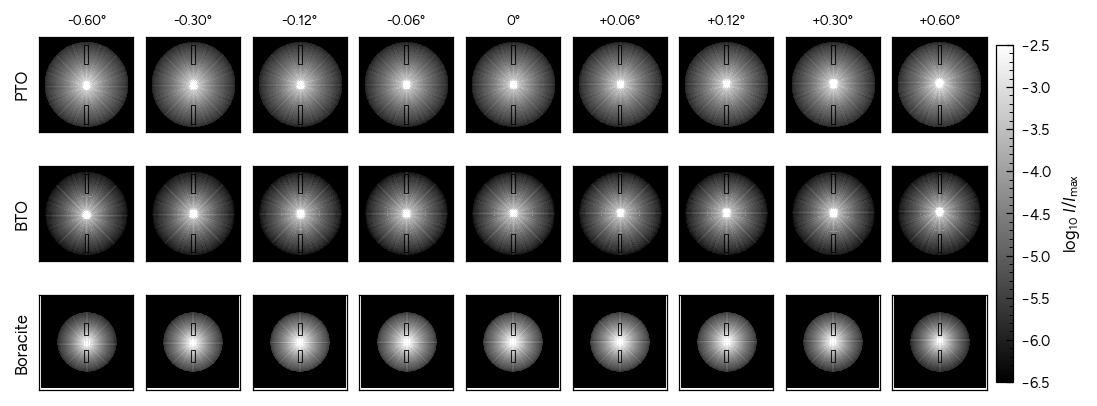

In [10]:
SHOW = [-0.6, -0.3, -0.12, -0.06, 0, 0.06, 0.12, 0.3, 0.6]
LIM = 12.5                                  # A^-1 shown


def friedel(k):
    """(I(q) - I(-q)) / (I(q) + I(-q)) in %, per tilt. bin(p + p_flip) = 2 bin(p) - bin(p - p_flip)."""
    img, dif = thumb[k]["img"], thumb[k]["dif"]
    tot = 2 * img - dif
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(tot > tot.max() * 1e-7, dif / tot * 100, np.nan)


def grid(field, cmap, vmin, vmax, label, show=SHOW):
    idx = [int(np.argmin(abs(T - t))) for t in show]
    fig, axes = plt.subplots(3, len(show), figsize=(7.2, 0.5 + 3 * 7.2 * 0.9 / len(show)), sharex=True,
                             sharey=True, gridspec_kw=dict(wspace=0.04, hspace=0.08))
    for row, k in zip(axes, DATA):
        h = N / 2 * KPP[k]; F = field(k); lo, hi, x0, x1 = BOX[k]
        for ax, i in zip(row, idx):
            ax.imshow(F[i], origin="lower", cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest",
                      extent=[-h, h, -h, h])
            for q0, q1 in ((lo, hi), (N + 1 - hi, N + 1 - lo)):     # box and mirror
                ax.add_patch(plt.Rectangle(((x0 - N/2) * KPP[k], (q0 - N/2) * KPP[k]), (x1 - x0) * KPP[k],
                                           (q1 - q0) * KPP[k], fill=False, lw=0.4, ec="black"))
            ax.set_xlim(-LIM, LIM); ax.set_ylim(-LIM, LIM); ax.set_xticks([]); ax.set_yticks([])
        row[0].set_ylabel(k)
    for ax, i in zip(axes[0], idx):
        ax.set_title(f"{T[i]:+.2f}°" if T[i] else "0°", fontsize="small")
    fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin, vmax)), ax=axes,
                 label=label, shrink=0.9, pad=0.01)
    return fig


logimg = lambda k: np.log10(thumb[k]["img"] / thumb[k]["img"][i0].max())
grid(logimg, "gray", -6.5, -2.5, r"$\log_{10}\,I/I_\mathrm{max}$")
plt.show()

By eye the patterns barely change. Dividing by the inversion through the centre,
$[I(\mathbf q)-I(-\mathbf q)]/[I(\mathbf q)+I(-\mathbf q)]$, removes everything the ±q comparison cannot
see. At 0° only the weak polar signal is left:

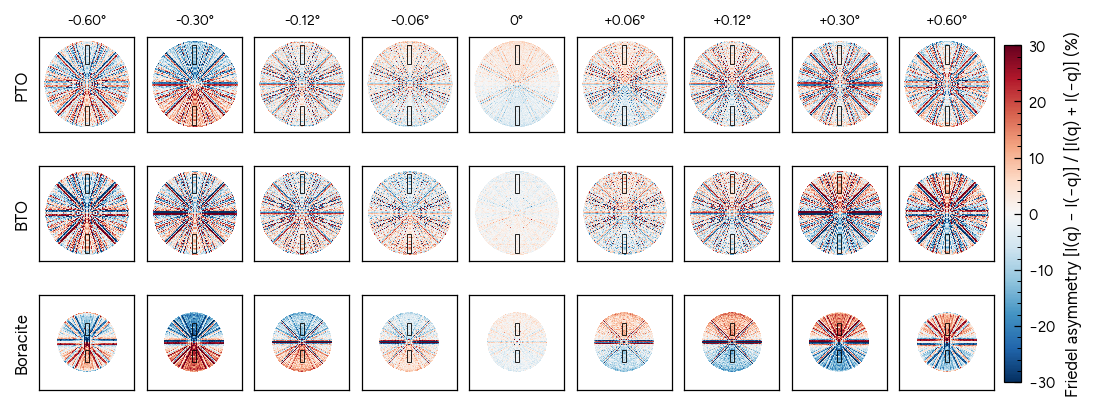

In [11]:
grid(friedel, "RdBu_r", -30, 30, "Friedel asymmetry [I(q) − I(−q)] / [I(q) + I(−q)] (%)")
plt.show()

- **0°:** a weak, smooth asymmetry along P (the polar signal).
- **Tilted:** 10–30 % asymmetry within 0.06°, concentrated on Kikuchi lines and band edges, with a
  hemisphere-scale tip on top. It reverses with the tilt direction.

Full resolution around the box (linear scale, contrast fixed at 0°). The dashed arc is the predicted
first-order Laue zone ring, $G=\sqrt{2/\lambda c_\mathrm{beam}}$, centred on the zone axis, which
moves with the crystal by $c\,t$:

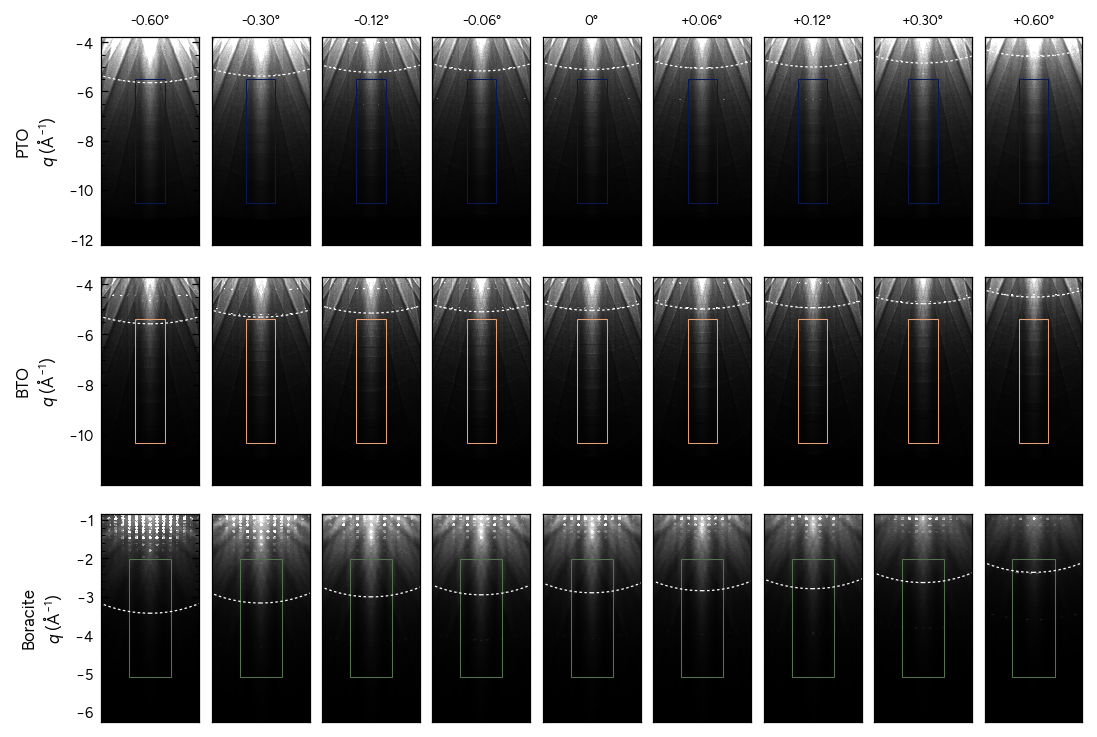

In [12]:
fig, axes = plt.subplots(3, len(SHOW), figsize=(7.2, 4.8), gridspec_kw=dict(wspace=0.04, hspace=0.12))
idx = [int(np.argmin(abs(T - t))) for t in SHOW]
ang = np.linspace(-np.pi, np.pi, 721)
for row, k in zip(axes, DATA):
    kpp = KPP[k]; crop = prof[k]["crop"]; lo, hi, x0, x1 = BOX[k]
    a = lo - 200
    ext = [-200 * kpp, 200 * kpp, (a - N/2) * kpp, (a + crop.shape[1] - N/2) * kpp]
    vlo, vhi = np.percentile(crop[i0], [1, 99.5])
    G = np.sqrt(2 / (LAMBDA * BEAM_REPEAT[k]))
    for ax, i in zip(row, idx):
        ax.imshow(crop[i], origin="lower", cmap="gray", vmin=vlo, vmax=vhi, extent=ext, aspect="auto",
                  interpolation="nearest")
        ax.add_patch(plt.Rectangle(((x0 - N/2) * kpp, (lo - N/2) * kpp), (x1 - x0) * kpp,
                                   (hi - lo) * kpp, fill=False, lw=0.5, ec=COLOURS[k]))
        pole = T[i] * PXDEG[k] * kpp                     # zone axis, A^-1 along axis 0
        ax.plot(G * np.sin(ang), pole + G * np.cos(ang), ls=(0, (2, 2)), lw=0.6, color="white")
        ax.set_xlim(ext[:2]); ax.set_ylim(ext[2:]); ax.set_xticks([])
        if ax is not row[0]: ax.set_yticks([])
    row[0].set_ylabel(f"{k}\n" + r"$q$ ($\mathrm{\AA}^{-1}$)")
for ax, i in zip(axes[0], idx):
    ax.set_title(f"{T[i]:+.2f}°" if T[i] else "0°", fontsize="small")
plt.show()

The FOLZ ring lies at the inner edge of the PTO/BTO boxes and inside boracite's, and it moves in and
out of the box as the crystal tilts, while the mirror box sees it move the other way.

#### Supplementary: Friedel maps at five tilts, and of the disk region on the same patterns

The disk map uses the central crop of the same 4096 patterns; boxes are the lattice-centred {100} and
{200} 1×3 ROIs and their mirrors. Note the tilts: the disk asymmetry already changes within ±0.06°.

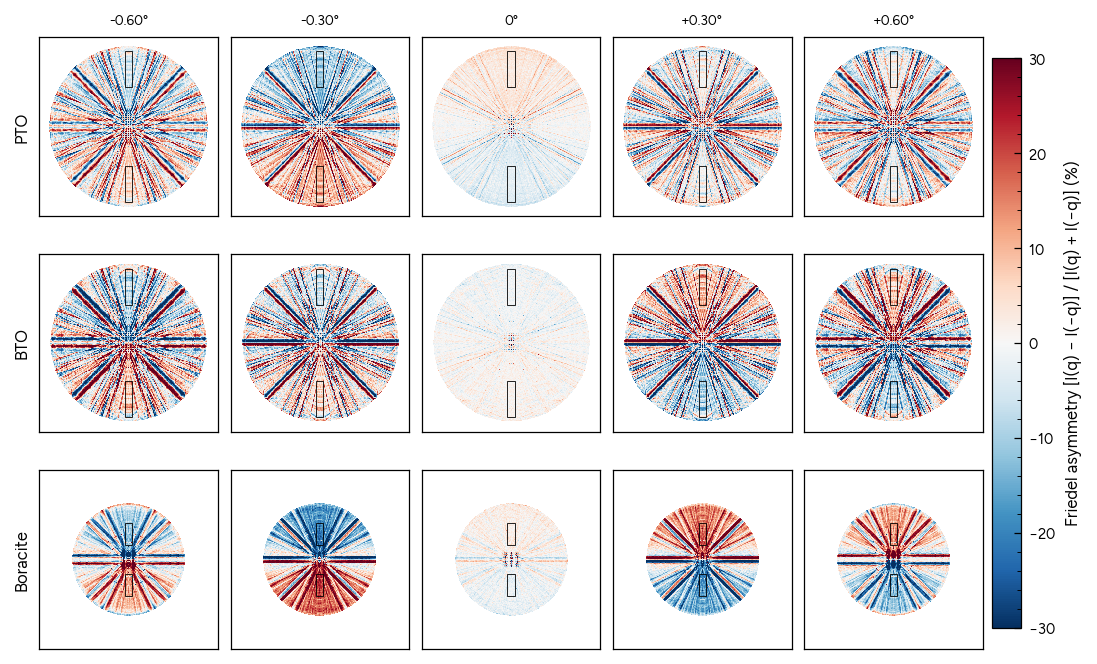

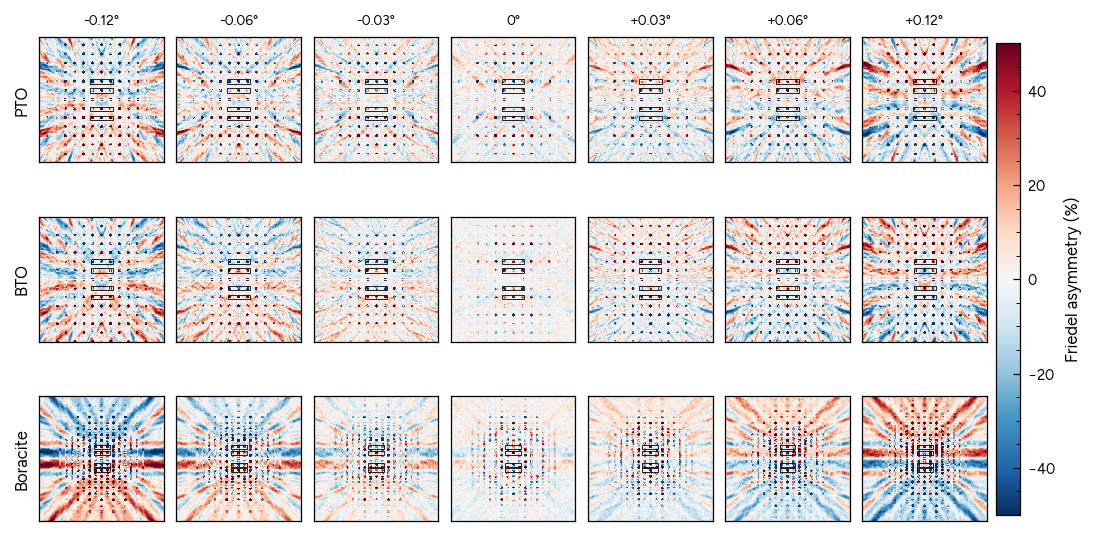

In [13]:
grid(friedel, "RdBu_r", -30, 30, "Friedel asymmetry [I(q) − I(−q)] / [I(q) + I(−q)] (%)",
     show=[-0.6, -0.3, 0, 0.3, 0.6])
plt.show()

DSHOW = [-0.12, -0.06, -0.03, 0, 0.03, 0.06, 0.12]
fig, axes = plt.subplots(3, len(DSHOW), figsize=(7.2, 3.6), gridspec_kw=dict(wspace=0.04, hspace=0.08))
for row, k in zip(axes, DATA):
    C = prof[k]["centre"].astype(np.float64)
    Cm = np.roll(C[:, ::-1, ::-1], 1, axis=(1, 2))           # crop index i -> 2*CW - i, i.e. -q
    h = int(1.75 / KPP[k])
    for ax, ts in zip(row, DSHOW):
        i = int(np.argmin(abs(T - ts)))
        tot = C[i] + Cm[i]
        with np.errstate(invalid="ignore", divide="ignore"):
            A = np.where(tot > tot.max() * 1e-5, (C[i] - Cm[i]) / tot * 100, np.nan)
        ax.imshow(A[CW - h:CW + h, CW - h:CW + h], origin="lower", cmap="RdBu_r", vmin=-50, vmax=50,
                  interpolation="nearest", extent=[-h, h, -h, h])
        for order in (1, 2):
            for y0, y1, x0, x1 in disk_boxes(k, order, 3):
                ax.add_patch(plt.Rectangle((x0 - N//2 - 0.5, y0 - N//2 - 0.5), x1 - x0, y1 - y0,
                                           fill=False, lw=0.4, ec="black"))
        ax.set_xticks([]); ax.set_yticks([])
    row[0].set_ylabel(k)
for ax, ts in zip(axes[0], DSHOW):
    ax.set_title(f"{ts:+.2f}°" if ts else "0°", fontsize="small")
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=plt.Normalize(-50, 50)), ax=axes,
             label="Friedel asymmetry (%)", shrink=0.9, pad=0.01)
plt.show()

### Tests of the obvious analysis explanations

Each row changes one thing and recomputes the tolerance (nearest sign change, paper frame). If an
explanation were right, the tolerance would grow a lot.
- **Box position:** low-order bands near the centre instead of the paper box.
- **Detector pixel size:** bin to 0.1 Å⁻¹ pixels, typical of experiments.
- **Crystal-fixed boxes:** move both boxes with the crystal (§1a), instead of fixing them on the detector.
- **Soft box edges:** a Hann taper over half the box height.

In [14]:
def shifted(P, box, shift):
    """metric with box and mirror both displaced by `shift` px (per tilt), about the displaced centre"""
    lo, hi = box[:2]; out = []
    for p, s in zip(P, shift):
        a = np.arange(lo, hi) + s; b = np.arange(N + 1 - hi, N + 1 - lo) + s
        ia, ib = np.interp(a, r, p), np.interp(b, r, p)
        out.append(((ia * a).sum() + (ib * b).sum()) / (ia.sum() + ib.sum()) - (N / 2 + s))
    return np.array(out)


def tapered(P, box):
    lo, hi = box[:2]; taper = (hi - lo) // 2
    w = np.zeros(N); w[lo:hi] = 1
    ramp = 0.5 - 0.5 * np.cos(np.linspace(0, np.pi, taper)); w[lo:lo+taper] = ramp; w[hi-taper:hi] = ramp[::-1]
    W = w + w[(N - r) % N]
    return (P * W * r).sum(1) / (P * W).sum(1) - N / 2


def binned(P, b):
    Pb = np.repeat(P[:, :N // b * b].reshape(len(P), -1, b).mean(2), b, axis=1)
    return np.pad(Pb, ((0, 0), (0, N - Pb.shape[1])), mode="edge")


tol = lambda k, raw: min(first_flip(*paper(k, T, -raw)))
BANDS = ((0.3, 1.3), (1.3, 2.8), (2.8, 5.5))
rows = {}
for k in DATA:
    P, kpp, box = prof[k]["prof0"], KPP[k], BOX[k]
    res = {"paper box": tol(k, com[k])}
    for qlo, qhi in BANDS:
        res[f"box at {qlo}–{qhi} Å⁻¹"] = tol(k, metric(P, (int(N/2 - qhi/kpp), int(N/2 - qlo/kpp))))
    res["0.1 Å⁻¹ detector pixels"] = tol(k, metric(binned(P, int(round(0.1 / kpp))), box))
    track = T * PXDEG[k]
    res["crystal-fixed boxes"] = tol(k, shifted(P, box, track))
    res["tapered edges"] = tol(k, tapered(P, box))
    rows[k] = res

print(f"{'tolerance (deg)':26s}" + "".join(f"{k:>10s}" for k in DATA))
for label in rows["PTO"]:
    print(f"{label:26s}" + "".join(f"{rows[k][label]:10.3f}" for k in DATA))

tolerance (deg)                  PTO       BTO  Boracite
paper box                      0.090     0.015     0.020
box at 0.3–1.3 Å⁻¹             0.037     0.016     0.001
box at 1.3–2.8 Å⁻¹             0.021     0.002     0.022
box at 2.8–5.5 Å⁻¹             0.065     0.012     0.017
0.1 Å⁻¹ detector pixels        0.089     0.015     0.020
crystal-fixed boxes            0.071     0.070     0.071
tapered edges                  0.090     0.015     0.018


Box position, pixel size and soft edges change nothing. **Crystal-fixed boxes** (the EBSD approach of
following the bands) are the one partial exception: BTO and boracite improve from 0.015–0.02° to 0.07°,
but PTO gets slightly worse (0.09 → 0.07°). All three then fail at about the same tilt, where the
beam-fixed intensity envelope sliding across the boxes takes over as the imbalance.

**Periodicity.** If successive reflections of the systematic row along P drove the structure, the curve
would repeat every $\theta_B$ of the first disk along P. The long-range sweeps have the frequency
resolution to check:

In [15]:
for k in DATA:
    L = np.load(f"figure_notebooks/cache_longrange/{k}.npz"); t, y = L["tilt"], L["com"]
    tg = np.linspace(-2.5, 2.5, 81); yg = np.interp(tg, t, y)          # BTO: fill its one missing tilt
    yg = yg - np.polyval(np.polyfit(tg, yg, 1), tg)
    F = np.abs(np.fft.rfft(yg * np.hanning(81), 2048)); f = np.fft.rfftfreq(2048, 0.0625)
    peaks = []
    for x in f[np.argsort(F)[::-1]]:
        if all(abs(x - p) > 0.4 for p in peaks): peaks.append(x)
        if len(peaks) == 3: break
    thB = np.degrees(LAMBDA * DISK_LATTICE[k][0] * KPP[k] / 2)
    print(f"{k:9s} 1/theta_B = {1/thB:5.2f} per deg | strongest: {', '.join(f'{p:.2f}' for p in peaks)} per deg")

PTO       1/theta_B =  6.99 per deg | strongest: 0.89, 0.24, 2.01 per deg
BTO       1/theta_B =  7.13 per deg | strongest: 0.28, 0.94, 3.49 per deg
Boracite  1/theta_B = 10.72 per deg | strongest: 0.57, 0.98, 1.81 per deg


No peak at 1/θ_B, so the low-order systematic row is not what sets the structure, consistent with §2b.

### The tilt breaks the ±q symmetry along P at first order

At the exact zone axis a centrosymmetric crystal gives $I(\mathbf q)=I(-\mathbf q)$; polarity breaks
this weakly (a Friedel-law violation). A tilt about *y* breaks it **directly** along P:
$+\mathbf g$ and $-\mathbf g$ acquire opposite excitation errors $s_{\pm g}\approx \mp g\,\theta$. The
perpendicular axis sees the same crystal, the same dynamical scattering, the same boxes and the same
tilts, but no first-order symmetry breaking:

In [16]:
for k in DATA:
    e, o = even_odd(kik[k])
    print(f"{k:9s} polar axis rms {kik[k].std():6.1f} px  (odd {o.std():6.1f}, even {e[TAU > 0].std():5.1f})"
          f" | non-polar axis rms {kik_ctrl[k].std():5.2f} px | ratio {kik[k].std()/kik_ctrl[k].std():4.0f}x")

PTO       polar axis rms   41.0 px  (odd   34.7, even  21.6) | non-polar axis rms  0.33 px | ratio  124x
BTO       polar axis rms   56.7 px  (odd   55.8, even  10.2) | non-polar axis rms  0.37 px | ratio  153x
Boracite  polar axis rms   74.0 px  (odd   73.6, even   7.2) | non-polar axis rms  0.55 px | ratio  136x


The tilt response is mostly **odd** in tilt, as a geometric symmetry breaking should be, and it is
100–150× larger along P than across it.

## 4 · Tilt *about* P (now simulated: the Kikuchi grid)

The 9 × 9 Kikuchi grid (±0.6°, 0.15° step, same metric and boxes, `figure_notebooks/cache_grid`) tests
the prediction that a tilt about P (rotation axis parallel to P, `tilt_x`) should be far less harmful,
because ±g along P then keep equal excitation errors to first order.

In [17]:
with zipfile.ZipFile("data/grids/kikuchi/PTO_kikuchi_grid.npz") as z:
    TG = np.load(io.BytesIO(z.open("tilt_y_values.npy").read()))
    assert np.allclose(np.load(io.BytesIO(z.open("tilt_x_values.npy").read())), TG)
j0 = int(np.argmin(abs(TG)))
print(f"{'':9s} {'zero tilt':>10s} | {'along P (tilt_y)':>18s} {'rms':>6s} | {'about P (tilt_x)':>18s} {'rms':>6s}   (A^-1)")
for k in DATA:
    gfull = np.load(f"figure_notebooks/cache_grid/{k}.npz")["full"]        # raw masked_com px, (ty, tx)
    assert tuple(np.load(f"figure_notebooks/cache_grid/{k}.npz")["box"]) == BOX[k]
    ty, vy = paper(k, TG, -gfull[:, j0])
    vx = -gfull[j0, :] * (1 if P_REVERSED[k] else -1)                     # tilt_x is not mirrored
    fy, fx = first_flip(ty, vy), first_flip(TG, vx)
    print(f"{k:9s} {vy[j0]*KPP[k]:+10.3f} | {fmt(fy[0]):>8s} {fmt(fy[1]):>9s} {np.std(vy-vy[j0])*KPP[k]:6.3f} | "
          f"{fmt(fx[0]):>8s} {fmt(fx[1]):>9s} {np.std(vx-vx[j0])*KPP[k]:6.3f}")

           zero tilt |   along P (tilt_y)    rms |   about P (tilt_x)    rms   (A^-1)
PTO           +0.208 |   0.073°      none  0.350 |     none      none  0.103
BTO           +0.079 |   0.041°      none  0.447 |   0.430°    0.421°  0.079
Boracite      -0.066 |     none    0.021°  0.422 |     none      none  0.011


Confirmed. About P, PTO and boracite keep their zero-tilt sign over the whole ±0.6° and BTO to 0.42°,
against 0.02–0.07° along P (interpolated across the grid's 0.15° step). The rms response is 4–40×
smaller about P than along it. In an experiment the mistilt has components along both axes, and only the component that
rotates P out of the beam-perpendicular plane hurts.

## 5 · Mapping opposite domains instead

For a down domain $y_\downarrow(t) = -y_\uparrow(-t)$, so at a common mistilt the contrast
$y_\uparrow - y_\downarrow = 2\,e(t)$ is twice the **even part**; the odd, geometric term cancels.

PTO       e(0) = +0.205 A^-1 | domain contrast keeps its sign to 0.150° (single domain: 0.090°)
BTO       e(0) = +0.068 A^-1 | domain contrast keeps its sign to 0.120° (single domain: 0.015°)
Boracite  e(0) = -0.074 A^-1 | domain contrast keeps its sign to 0.180° (single domain: 0.020°)


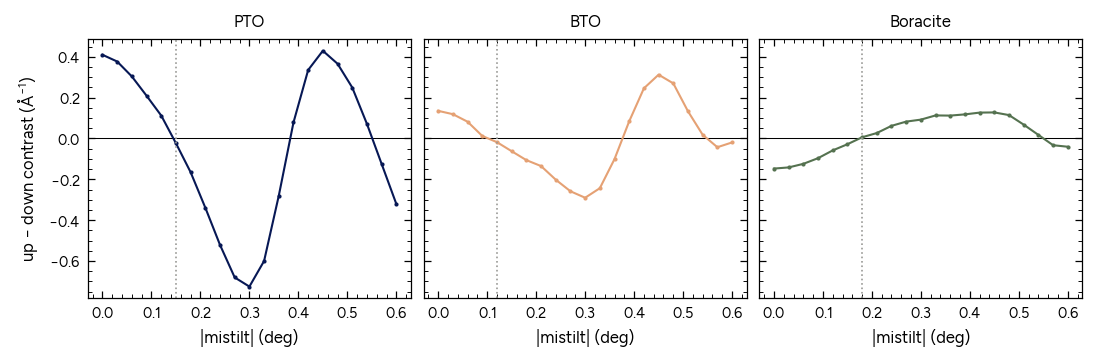

In [18]:
def even_flip(t, y):
    e, _ = even_odd(y); pos = t > 0
    bad = t[pos][np.sign(e[pos]) != np.sign(e[np.argmin(abs(t))])]
    return bad.min() if len(bad) else np.inf


fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.3), sharey=True)
for ax, k in zip(axes, DATA):
    e, _ = even_odd(kik[k] * KPP[k]); f = even_flip(TAU, kik[k])
    print(f"{k:9s} e(0) = {e[i0]:+.3f} A^-1 | domain contrast keeps its sign to {fmt(f)} "
          f"(single domain: {fmt(min(first_flip(TAU, kik[k])))})")
    ax.axhline(0, color="black", lw=0.5)
    ax.plot(TAU[TAU >= 0], 2 * e[TAU >= 0], "-o", ms=2, mew=0, color=COLOURS[k])
    ax.axvline(f, color=GREY, ls=":", lw=0.8)
    ax.set_title(k); ax.set_xlabel("|mistilt| (deg)")
axes[0].set_ylabel(r"up − down contrast ($\mathrm{\AA}^{-1}$)")
plt.show()

## 6 · Disks vs Kikuchi, on the same patterns

Every ROI, the Kikuchi COM and the whole-pattern asymmetry, all measured on the same 41 patterns and
all in the paper frame. "Domain" is where the even part first changes sign (step-limited, 0.03°).

In [19]:
print(f"{'':9s} {'method':18s} {'at 0':>9s} {'flip −':>8s} {'flip +':>8s} {'tolerance':>10s} {'domain':>8s}")
for k in DATA:
    entries = [("Kikuchi COM", kik[k] * KPP[k], "A^-1"), ("whole pattern", whole[k], "%")]
    entries += [(f"{{{o}00}} 1×{n}", disk[k][(o, n)], "%") for o, n in ROIS[k]]
    for label, v, u in entries:
        f = first_flip(TAU, v)
        z = f"{v[i0]:+.3f}" if u == "A^-1" else f"{v[i0]:+.1f}%"
        print(f"{k:9s} {label:18s} {z:>9s} {fmt(f[0]):>8s} {fmt(f[1]):>8s} {fmt(min(f)):>10s} "
              f"{fmt(even_flip(TAU, v)):>8s}")
    print()

          method                  at 0   flip −   flip +  tolerance   domain
PTO       Kikuchi COM           +0.205   0.090°   0.311°     0.090°   0.150°
PTO       whole pattern          -7.7%     none   0.055°     0.055°   0.360°
PTO       {100} 1×1              +9.4%   0.008°   0.243°     0.008°   0.090°
PTO       {100} 1×3             -31.2%     none   0.140°     0.140°     none
PTO       {100} 1×5             -30.3%     none   0.135°     0.135°   0.270°
PTO       {200} 1×1             -74.5%     none   0.042°     0.042°   0.300°
PTO       {200} 1×3             -60.1%     none   0.036°     0.036°   0.330°
PTO       {200} 1×5             -60.3%     none   0.040°     0.040°   0.330°
PTO       {300} 1×1             -33.6%     none   0.025°     0.025°   0.090°
PTO       {300} 1×3              -8.5%   0.020°   0.045°     0.020°   0.060°
PTO       {300} 1×5              -8.4%     none   0.037°     0.037°   0.060°

BTO       Kikuchi COM           +0.068   0.015°     none     0.015°   0.120

On identical patterns, the best Friedel-pair ROI is **more** tilt-tolerant than the Kikuchi COM in all
three materials (0.14 vs 0.09°, 0.04–0.05 vs 0.015°, 0.18 vs 0.02°). The literature claim that Kikuchi bands
are less sensitive to mistilt does not reproduce here, consistent with §2b: the Kikuchi boxes sit on
the FOLZ ring, where the rocking scale is shortest.

## Literature consulted

- [Imaging of nanoscale polar textures in quantum paraelectric SrTiO₃](https://pmc.ncbi.nlm.nih.gov/articles/PMC13441873/).
  COM of isolated Kikuchi bands, 1 mrad convergence, 0.1 Å⁻¹ pixels, 53–69 nm thick. Mistilt
  "systematically evaluated" in its supplementary (not read).
- [Polarity determination in EBSD patterns using the Hough transformation](https://doi.org/10.1017/S1431927621012605)
  and [Kikuchi pattern analysis of noncentrosymmetric crystals](https://journals.iucr.org/paper?S1600576715014016=).
  EBSD locates each band first and compares its own profile, so the frame moves with the crystal.
- The "less sensitive to mistilt" claim: 4D-STEM benchmarking literature, e.g.
  [Scientific Reports 2026](https://www.nature.com/articles/s41598-026-57754-1).